# 03 · Baseline, candidate method and evaluation
**Week 4.** We have no labelled "incident" column, so we evaluate in two layers:

1. **Expected consumption (prediction).** Baseline 1 = seasonal naive (same month last year). Baseline 2 = persistence (last actual month). Candidate = gradient boosting that learns a *correction* to persistence from season, weather, size and gap history. Metric: error on held-out *future* months. The method used for flagging is the one with the lowest error on the **validation** year (chosen before looking at test).
2. **Decision rules (anomaly flags).** Rule A = one citywide threshold on gallons/apartment/day. Rule B = development-specific: flag a month when actual use is far from the candidate's expected use (robust z-score of the residual). We compare rules on flag rate, agreement with independent 311 disruption spikes, sensitivity to the threshold, subgroup effects and cost of errors.

**Time-based split:** train ≤ 2021-12 · validation 2022 · test 2023-01 onwards. No shuffling. Thresholds and scales are learned on train/validation only.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import water_utils as wu
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.tight_layout()
    fig.savefig(wu.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
from sklearn.inspection import permutation_importance

In [2]:
p = wu.add_features(wu.load_panel())
print(p["period"].value_counts())
print("Rows usable as model target (actual reads with a value):", p["y"].notna().sum())

period
train    7308
test     1570
valid     731
Name: count, dtype: int64
Rows usable as model target (actual reads with a value): 6396


## 1. Leakage checks
- Lag features are shifted: the value used for month *t* comes from month *t−1* or earlier.
- Only **actual** reads feed the target and the lags; estimated values never enter.
- The split is by time; the test months are later than every training month.
- The robust scale for Rule B and the percentiles for Rule A come from train/validation only.
- 311 spike thresholds use training years only.

In [3]:
s = p.sort_values(["tds", "month"])
prev = s.groupby("tds")["y"].shift(1)
assert np.allclose(s["lag1"].fillna(-9), prev.fillna(-9)), "lag1 is not the previous month"
assert p.loc[p.period == "train", "revenue_month"].max() < p.loc[p.period == "test", "revenue_month"].min()
assert "y" not in wu.FEATURES and "y_raw" not in wu.FEATURES and "hcf_per_day" not in wu.FEATURES
print("Leakage checks passed: lags are past-only, split is chronological, target not in features.")

Leakage checks passed: lags are past-only, split is chronological, target not in features.


## 2. Fit the baselines and the candidate
All three methods are scored on exactly the same development-months.

In [4]:
data = p[p["y"].notna()].copy()
train = data[data.period == "train"]
model = wu.fit_candidate(train)
data["pred_base"] = wu.baseline_predict(data)
data["pred_pers"] = wu.persistence_predict(data)
data["pred_cand"] = wu.candidate_predict(model, data)
train, valid, test = (data[data.period == k] for k in ("train", "valid", "test"))

METHODS = (("Baseline 1: seasonal naive (same month last year)", "pred_base"),
           ("Baseline 2: persistence (last actual month)", "pred_pers"),
           ("Candidate: gradient boosting correction to persistence", "pred_cand"))
rows = []
for split, df in (("train", train), ("valid", valid), ("test", test)):
    m = df[["pred_base", "pred_pers", "pred_cand"]].notna().all(axis=1)   # SAME rows for every method
    for name, col in METHODS:
        rows.append({"split": split, "method": name, **wu.metrics(df.loc[m, "y"], df.loc[m, col])})
metric_table = pd.DataFrame(rows).round(3)
metric_table.to_csv(wu.ROOT / "reports" / "metric_comparison.csv", index=False)
metric_table

,split,method,n,MAE_log,RMSE_log,MAE_hcf_day,MedAPE_%
0,train,Baseline 1: seasonal naive (same month last year),4680,0.232,0.406,9.402,15.014
1,train,Baseline 2: persistence (last actual month),4680,0.113,0.236,5.121,6.694
2,train,Candidate: gradient boosting correction to per...,4680,0.101,0.225,4.602,5.421
3,valid,Baseline 1: seasonal naive (same month last year),501,0.231,0.427,6.895,14.316
4,valid,Baseline 2: persistence (last actual month),501,0.129,0.306,4.440,6.684
5,valid,Candidate: gradient boosting correction to per...,501,0.127,0.300,4.375,7.237
6,test,Baseline 1: seasonal naive (same month last year),955,0.211,0.363,8.560,14.985
7,test,Baseline 2: persistence (last actual month),955,0.135,0.288,5.603,7.431
8,test,Candidate: gradient boosting correction to per...,955,0.133,0.284,5.428,7.296


In [5]:
v = metric_table[metric_table.split == "valid"].set_index("method")
t = metric_table[metric_table.split == "test"].set_index("method")
best_name = v["MAE_log"].idxmin()
BEST = dict(METHODS)[best_name]
print(f"Chosen on VALIDATION (lowest MAE_log): {best_name}")
c, b1, b2 = METHODS[2][0], METHODS[0][0], METHODS[1][0]
print(f"Test MAE_log improvement of candidate over seasonal naive: {100 * (1 - t.loc[c, 'MAE_log'] / t.loc[b1, 'MAE_log']):.1f}%  (success measure: >= 10%)")
print(f"Test MAE_log improvement of candidate over persistence:    {100 * (1 - t.loc[c, 'MAE_log'] / t.loc[b2, 'MAE_log']):.1f}%")
print(f"Test MAE_log improvement of persistence over seasonal naive: {100 * (1 - t.loc[b2, 'MAE_log'] / t.loc[b1, 'MAE_log']):.1f}%")

Chosen on VALIDATION (lowest MAE_log): Candidate: gradient boosting correction to persistence
Test MAE_log improvement of candidate over seasonal naive: 37.0%  (success measure: >= 10%)
Test MAE_log improvement of candidate over persistence:    1.5%
Test MAE_log improvement of persistence over seasonal naive: 36.0%


## 3. Subgroup errors (does the model work equally well everywhere?)

In [6]:
test = test.copy()
test["size_group"] = pd.qcut(test["apartments"], 3, labels=["small", "medium", "large"])
sub = []
for col in ("borough", "size_group"):
    for g, d in test.groupby(col, observed=True):
        d = d[d[["pred_base", "pred_pers", "pred_cand"]].notna().all(axis=1)]
        sub.append({"subgroup": f"{col}={g}", "n": len(d),
                    "MAE_log_seasonal_naive": wu.metrics(d["y"], d["pred_base"])["MAE_log"],
                    "MAE_log_persistence": wu.metrics(d["y"], d["pred_pers"])["MAE_log"],
                    "MAE_log_candidate": wu.metrics(d["y"], d["pred_cand"])["MAE_log"]})
subgroup_errors = pd.DataFrame(sub).round(3)
subgroup_errors.to_csv(wu.ROOT / "reports" / "subgroup_errors.csv", index=False)
subgroup_errors

,subgroup,n,MAE_log_seasonal_naive,MAE_log_persistence,MAE_log_candidate
0,borough=BRONX,284,0.141,0.091,0.087
1,borough=BROOKLYN,183,0.248,0.168,0.166
2,borough=MANHATTAN,319,0.240,0.143,0.143
3,borough=QUEENS,141,0.220,0.144,0.141
4,borough=STATEN ISLAND,28,0.287,0.243,0.233
5,size_group=small,365,0.209,0.111,0.111
6,size_group=medium,297,0.149,0.096,0.096
7,size_group=large,293,0.276,0.205,0.199


## 4. Which inputs matter? (permutation importance on the validation year)

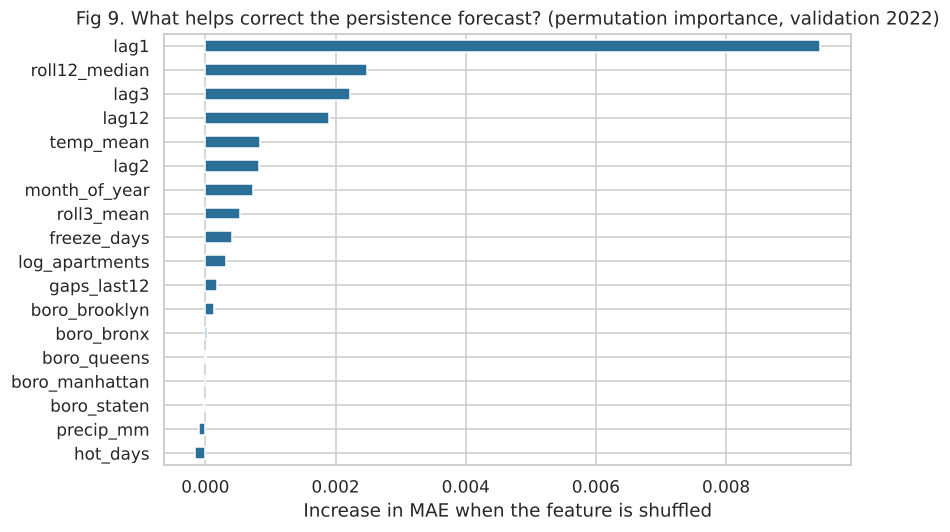

In [7]:
vv = valid[valid["pred_pers"].notna()]
pi = permutation_importance(model, vv[wu.FEATURES], vv["y"] - vv["pred_pers"], n_repeats=5, random_state=0,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=wu.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot(kind="barh", color="#2a6f97", ax=ax)
ax.set_xlabel("Increase in MAE when the feature is shuffled")
ax.set_title("Fig 9. What helps correct the persistence forecast? (permutation importance, validation 2022)")
save(fig, "fig9_feature_importance")

## 5. Decision rules: Rule A (citywide threshold) vs Rule B (development-specific residual)

In [8]:
# Rule B scale from VALIDATION residuals (not test)
data["pred_best"] = data[BEST]            # the method chosen on validation
data["resid"] = data["y"] - data["pred_best"]
med, scale = wu.robust_scale(data.loc[data.period == "valid", "resid"])
# Rule A percentiles from TRAIN actual months of WHOLE-metered developments (not test).
# Rule A needs gallons per apartment, which is meaningless for partially metered developments.
ga = data.loc[(data.period == "train") & (data.metering == "whole"), "gal_per_apt_day"].replace([np.inf, -np.inf], np.nan).dropna()
lowA, highA = ga.quantile(0.05), ga.quantile(0.95)
print(f"Rule B: residual median {med:.3f}, robust sd {scale:.3f} | Rule A band: {lowA:.0f}-{highA:.0f} gal/apt/day")

data["spike_311"] = wu.complaint_spikes(data)
test = data[data.period == "test"].copy()
test["flag_A"] = wu.flag_by_threshold(test["gal_per_apt_day"].where(test["metering"] == "whole"), lowA, highA)
test["flag_B"] = wu.flag_by_residual(test["resid"], med, scale, k=3.0)

top_tercile = test["apartments"] >= test["apartments"].quantile(2/3)
common = test["flag_A"].notna() & test["flag_B"].notna()   # fair comparison: the SAME development-months

def summarise(flag_col, label, rows):
    d = test[rows]
    c = wu.corroboration(d[flag_col], d["spike_311"])
    f = d[flag_col].fillna(0) != 0
    return {"rule": label, "scored_dev_months": int(d[flag_col].notna().sum()), **c,
            "devs_flagged": d.loc[f, "tds"].nunique(),
            "%_flags_in_largest_third": 100 * (f & top_tercile[rows]).sum() / max(f.sum(), 1)}

rules = pd.DataFrame([summarise("flag_A", "A: citywide 5th/95th percentile (same rows)", common),
                      summarise("flag_B", "B: residual |z| > 3 (same rows)", common),
                      summarise("flag_B", "B: residual |z| > 3 (all developments)", test["flag_B"].notna())]).round(2)
both = ((test.flag_A.fillna(0) != 0) & (test.flag_B.fillna(0) != 0) & common).sum()
either = (((test.flag_A.fillna(0) != 0) | (test.flag_B.fillna(0) != 0)) & common).sum()
print(f"Agreement (Jaccard) between rules: {both / max(either, 1):.2f}")
rules.to_csv(wu.ROOT / "reports" / "rule_comparison.csv", index=False)
rules

Rule B: residual median -0.000, robust sd 0.085 | Rule A band: 57-426 gal/apt/day
Agreement (Jaccard) between rules: 0.13


,rule,scored_dev_months,flag_rate_%,n_flagged,in_spike_%,base_spike_%,lift,devs_flagged,%_flags_in_largest_third
0,A: citywide 5th/95th percentile (same rows),691,12.45,86,19.77,7.67,2.58,13,34.88
1,B: residual |z| > 3 (same rows),691,8.25,57,26.32,7.67,3.43,22,10.53
2,B: residual |z| > 3 (all developments),955,11.10,106,17.92,7.33,2.45,30,51.89


**How to read this table.** `flag_rate_%` = workload (share of development-months sent for inspection). `in_spike_%` vs `base_spike_%`: if flagged months fall in 311 disruption spikes more often than average, `lift` > 1 is weak independent support. `%_flags_in_largest_third` shows whether a rule concentrates on big developments. The first two rows compare both rules on exactly the same development-months (whole-metered developments only); the third row shows Rule B can also score the partially metered developments, which Rule A cannot.

## 6. Sensitivity analysis (how much does the threshold choice matter?)

In [9]:
sens = []
for k in (2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0):
    f = wu.flag_by_residual(test["resid"], med, scale, k=k)
    sens.append({"rule": "B", "threshold": f"|z| > {k}", **wu.corroboration(f, test["spike_311"])})
for q in (0.90, 0.95, 0.975, 0.99):
    lo, hi = ga.quantile(1 - q), ga.quantile(q)
    f = wu.flag_by_threshold(test["gal_per_apt_day"].where(test["metering"] == "whole"), lo, hi)
    sens.append({"rule": "A", "threshold": f"outside {100*(1-q):.1f}-{100*q:.1f} pct", **wu.corroboration(f, test["spike_311"])})
sensitivity = pd.DataFrame(sens).round(2)
sensitivity.to_csv(wu.ROOT / "reports" / "sensitivity_table.csv", index=False)
sensitivity

,rule,threshold,flag_rate_%,n_flagged,in_spike_%,base_spike_%,lift
0,B,|z| > 2.0,18.12,173,12.14,7.33,1.66
1,B,|z| > 2.5,14.76,141,14.18,7.33,1.94
2,B,|z| > 3.0,11.10,106,17.92,7.33,2.45
3,B,|z| > 3.5,8.80,84,19.05,7.33,2.60
4,B,|z| > 4.0,7.64,73,20.55,7.33,2.80
5,B,|z| > 5.0,5.65,54,25.93,7.33,3.54
6,B,|z| > 6.0,4.82,46,23.91,7.33,3.26
7,A,outside 10.0-90.0 pct,19.94,139,14.39,7.60,1.89
8,A,outside 5.0-95.0 pct,12.48,87,19.54,7.60,2.57
9,A,outside 2.5-97.5 pct,7.60,53,22.64,7.60,2.98


### Choosing the operating threshold on the VALIDATION year
Crew capacity target: at most 5% of development-months flagged. We pick the smallest k whose flag rate on the validation year (2022) is at most 5%, then report how it performs on test. Choosing k from the test table above would be leakage.

In [10]:
val = data[data.period == "valid"]
vrows = []
for k in np.arange(2.0, 8.01, 0.5):
    vf = wu.flag_by_residual(val["resid"], med, scale, k=k)
    tf = wu.flag_by_residual(test["resid"], med, scale, k=k)
    vrows.append({"k": k, "valid_flag_rate_%": 100 * (vf.dropna() != 0).mean(),
                  "test_flag_rate_%": 100 * (tf.dropna() != 0).mean(),
                  "test_lift": wu.corroboration(tf, test["spike_311"])["lift"]})
kt = pd.DataFrame(vrows).round(2)
K = float(kt.loc[kt["valid_flag_rate_%"] <= 5, "k"].min())
test["flag_B_op"] = wu.flag_by_residual(test["resid"], med, scale, k=K)
kt.to_csv(wu.ROOT / "reports" / "threshold_choice.csv", index=False)
print(f"Operating threshold chosen on validation: |z| > {K}")
kt

Operating threshold chosen on validation: |z| > 4.5


,k,valid_flag_rate_%,test_flag_rate_%,test_lift
0,2.0,16.17,18.12,1.66
1,2.5,11.58,14.76,1.94
2,3.0,9.38,11.10,2.45
3,3.5,7.39,8.80,2.60
4,4.0,6.59,7.64,2.80
5,4.5,4.39,5.97,3.35
6,5.0,4.19,5.65,3.54
7,5.5,3.79,5.24,3.27
8,6.0,3.39,4.82,3.26
9,6.5,2.99,4.19,3.07


## 7. Measurement gaps vs real incidents
Apply Rule B to **every** billed month, including estimated and zero reads (using `y_raw`). If gap months get flagged far more often than actual months, a naive anomaly detector would send crews to fix "incidents" that are really unread meters. That is why gaps are labelled and handled first.

In [11]:
allm = p[p.period == "test"].copy()
allm["pred_best"] = {"pred_base": wu.baseline_predict, "pred_pers": wu.persistence_predict}.get(
    BEST, lambda d: wu.candidate_predict(model, d))(allm)
allm["resid_raw"] = allm["y_raw"] - allm["pred_best"]
allm["flag_raw"] = wu.flag_by_residual(allm["resid_raw"], med, scale, k=3.0)
gap_vs_flag = (allm[allm.gap_type != "missing_bill"].groupby("gap_type")["flag_raw"]
               .agg(dev_months="size", flag_rate_pct=lambda s: 100 * (s.fillna(0) != 0).mean()).round(1))
gap_vs_flag.to_csv(wu.ROOT / "reports" / "gap_vs_flag.csv")
gap_vs_flag

,dev_months,flag_rate_pct
gap_type,,
actual,983,10.8
estimated,510,8.8
zero_read,42,33.3


## 8. Cost of errors
- **Missed incident (false negative):** water keeps leaking. Price it with the average water & sewer charge per HCF from the training years.
- **False alert (false positive):** a crew visit with nothing found. Set `CREW_VISIT_COST_USD` with your stakeholder assumption and state it in the report.

In [12]:
CREW_VISIT_COST_USD = 400   # ASSUMPTION - change and justify in the report
tr = p[(p.period == "train") & (p.gap_type == "actual")]
usd_per_hcf = tr["charges"].sum() / tr["hcf"].sum()
hi_flags = test[test["flag_B_op"] == 1].copy()
hi_flags["excess_hcf_month"] = (np.expm1(hi_flags["y"]) - np.expm1(hi_flags["pred_best"])) * 30.4
hi_flags["excess_usd"] = hi_flags["excess_hcf_month"] * usd_per_hcf
ex = hi_flags["excess_usd"].sort_values(ascending=False)
visit_total = len(hi_flags) * CREW_VISIT_COST_USD
cost = pd.DataFrame({
    "item": ["USD per HCF (water + sewer, train years)", f"High-use flags in test period (Rule B, operating k={K})",
             "Excess water, all flags, HCF", "Value of excess water, all flags, USD",
             "Value excluding the single largest flag, USD (robustness)", "Median value per flag, USD",
             "Inspection cost if every flag is visited, USD (assumption)",
             "Break-even share of flags that must be real (all flags)",
             "Break-even share excluding the largest flag"],
    "value": [usd_per_hcf, len(hi_flags), hi_flags["excess_hcf_month"].sum(), ex.sum(),
              ex.iloc[1:].sum(), ex.median(), visit_total,
              visit_total / max(ex.sum(), 1), visit_total / max(ex.iloc[1:].sum(), 1)]}).round(3)
cost.to_csv(wu.ROOT / "reports" / "cost_of_errors.csv", index=False)
display(cost)
print("Five largest flags (check these by hand: real leak, or a billing/meter error?)")
hi_flags.assign(expected_hcf_day=np.expm1(hi_flags["pred_best"])).nlargest(5, "excess_usd")[["development", "borough", "revenue_month", "hcf_per_day", "expected_hcf_day", "excess_hcf_month", "excess_usd"]].round(1)

,item,value
0,"USD per HCF (water + sewer, train years)",9.637
1,"High-use flags in test period (Rule B, operati...",24.000
2,"Excess water, all flags, HCF",40235.663
3,"Value of excess water, all flags, USD",387739.536
4,"Value excluding the single largest flag, USD (...",125748.388
5,"Median value per flag, USD",3195.711
6,"Inspection cost if every flag is visited, USD ...",9600.000
7,Break-even share of flags that must be real (a...,0.025
8,Break-even share excluding the largest flag,0.076


Five largest flags (check these by hand: real leak, or a billing/meter error?)


,development,borough,revenue_month,hcf_per_day,expected_hcf_day,excess_hcf_month,excess_usd
8745,SAMUEL (CITY),MANHATTAN,2023-06,1030.3,136.0,27186.8,261991.1
8213,HOWARD AVENUE-PARK PLACE,BROOKLYN,2024-01,110.8,28.7,2496.3,24056.6
4855,EAST 165TH STREET-BRYANT AVENUE,BRONX,2023-10,103.6,53.9,1510.5,14556.5
6991,RALPH AVENUE REHAB,BROOKLYN,2024-01,120.7,71.3,1500.0,14455.4
6980,RALPH AVENUE REHAB,BROOKLYN,2023-02,81.6,42.4,1192.6,11492.5


## 9. Failure cases (largest test errors) - inspect these by hand

In [13]:
fail = test.assign(abs_err=(test["y"] - test["pred_best"]).abs(),
                   expected_hcf_day=np.expm1(test["pred_best"])).nlargest(10, "abs_err")
fail[["tds", "development", "borough", "revenue_month", "hcf_per_day", "expected_hcf_day", "n_meters",
      "share_estimated", "abs_err"]].round(3)

,tds,development,borough,revenue_month,hcf_per_day,expected_hcf_day,n_meters,share_estimated,abs_err
2181,97,TAFT,MANHATTAN,2023-06,32.581,2.704,1.0,0.000,2.205
8745,377,SAMUEL (CITY),MANHATTAN,2023-06,1030.300,135.998,22.0,0.227,2.019
8746,377,SAMUEL (CITY),MANHATTAN,2023-07,140.364,1014.608,22.0,0.273,1.972
2176,97,TAFT,MANHATTAN,2023-01,2.600,23.888,1.0,0.000,1.933
2187,97,TAFT,MANHATTAN,2023-12,3.270,24.559,1.0,0.000,1.789
824,28,MELROSE,BRONX,2023-03,6.000,0.257,1.0,0.000,1.717
2182,97,TAFT,MANHATTAN,2023-07,5.034,32.536,1.0,0.000,1.715
901,37,RANGEL,MANHATTAN,2025-03,12.207,1.761,3.0,0.333,1.565
1943,91,BAISLEY PARK,QUEENS,2023-01,6.500,0.739,1.0,0.000,1.461
2516,114,STAPLETON,STATEN ISLAND,2025-02,4.655,0.442,1.0,0.000,1.367


## 10. Recurrence: the priority list (answers the decision question)
A development is **unreliable** when it is flagged repeatedly. We combine abnormal-use flags (Rule B at the operating threshold chosen on validation) and measurement-gap months over the test period (Jan 2023 - May 2025, 29 months). Rules: 6+ gap months -> fix metering first (abnormal-use flags cannot be trusted while readings are missing); otherwise 3+ abnormal months -> inspect; otherwise monitor. `metering` = partial means the flags concern a store or community-centre meter, not the whole development.

In [14]:
pt = p[p.period == "test"]
rec = (pt.groupby(["tds", "development", "borough", "metering"], dropna=False)
         .agg(months=("revenue_month", "size"), gap_months=("is_gap", "sum"), apartments=("apartments", "first"))
         .join(test.groupby("tds").agg(high_flags=("flag_B_op", lambda s: (s == 1).sum()),
                                       low_flags=("flag_B_op", lambda s: (s == -1).sum())), on="tds")
         .fillna({"high_flags": 0, "low_flags": 0}))
rec["abnormal_months"] = rec["high_flags"] + rec["low_flags"]
rec["action"] = np.select(
    [rec["gap_months"] >= 6, rec["abnormal_months"] >= 3],
    ["Fix metering first (recurring gaps)", "Inspect for leaks / supply issues (recurring abnormal use)"],
    default="Monitor")
priority = rec.sort_values(["abnormal_months", "gap_months"], ascending=False).reset_index()
priority.to_csv(wu.ROOT / "reports" / "priority_list.csv", index=False)
print(priority["action"].value_counts())
priority.head(20)

action
Fix metering first (recurring gaps)                           28
Monitor                                                       24
Inspect for leaks / supply issues (recurring abnormal use)     8
Name: count, dtype: int64


,tds,development,borough,metering,months,gap_months,apartments,high_flags,low_flags,abnormal_months,action
0,143,REHAB PROGRAM (COLLEGE POINT),QUEENS,whole,29,0,13.0,3.0,4.0,7.0,Inspect for leaks / supply issues (recurring a...
1,37,RANGEL,MANHATTAN,partial,29,0,984.0,2.0,3.0,5.0,Inspect for leaks / supply issues (recurring a...
2,97,TAFT,MANHATTAN,partial,29,5,1470.0,1.0,3.0,4.0,Inspect for leaks / supply issues (recurring a...
3,83,MARLBORO,BROOKLYN,partial,29,1,1765.0,1.0,3.0,4.0,Inspect for leaks / supply issues (recurring a...
4,28,MELROSE,BRONX,partial,29,0,1023.0,2.0,2.0,4.0,Inspect for leaks / supply issues (recurring a...
5,339,HOWARD AVENUE,BROOKLYN,whole,21,8,150.0,2.0,1.0,3.0,Fix metering first (recurring gaps)
6,352,RALPH AVENUE REHAB,BROOKLYN,whole,22,8,118.0,2.0,1.0,3.0,Fix metering first (recurring gaps)
7,114,STAPLETON,STATEN ISLAND,partial,29,1,693.0,2.0,1.0,3.0,Inspect for leaks / supply issues (recurring a...
8,27,SMITH,MANHATTAN,partial,29,0,1935.0,1.0,2.0,3.0,Inspect for leaks / supply issues (recurring a...
9,514,WHITMAN,BROOKLYN,partial,29,0,1659.0,1.0,2.0,3.0,Inspect for leaks / supply issues (recurring a...


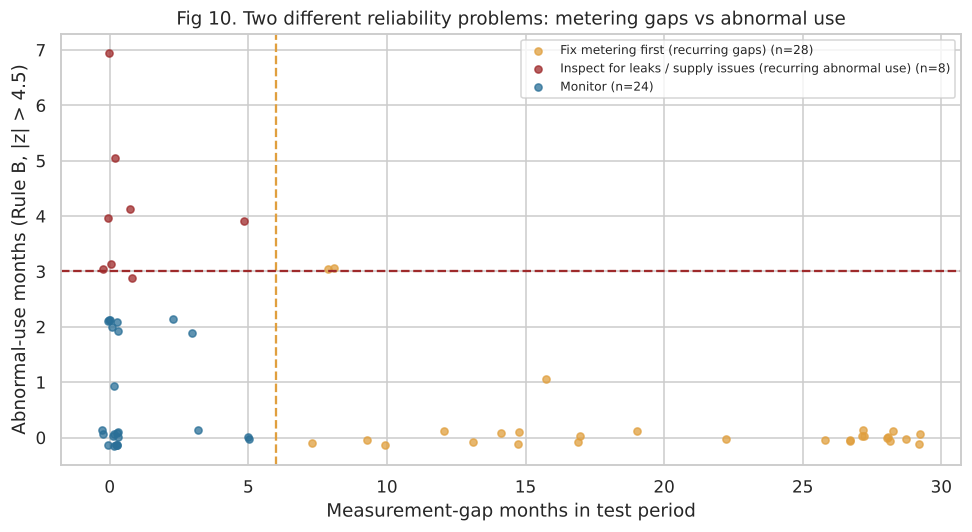

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
jit = np.random.default_rng(0)
colors = {"Fix metering first (recurring gaps)": "#e09f3e",
          "Inspect for leaks / supply issues (recurring abnormal use)": "#9e2a2b", "Monitor": "#2a6f97"}
for act, g in priority.groupby("action"):
    ax.scatter(g["gap_months"] + jit.uniform(-.3, .3, len(g)), g["abnormal_months"] + jit.uniform(-.15, .15, len(g)),
               s=22, alpha=.75, color=colors[act], label=f"{act} (n={len(g)})")
ax.axvline(6, color="#e09f3e", ls="--"); ax.axhline(3, color="#9e2a2b", ls="--")
ax.legend(fontsize=8, loc="upper right")
ax.set_xlabel("Measurement-gap months in test period"); ax.set_ylabel(f"Abnormal-use months (Rule B, |z| > {K})")
ax.set_title("Fig 10. Two different reliability problems: metering gaps vs abnormal use")
save(fig, "fig10_priority_quadrants")

## 11. Sample size for the proposed A/B test (design only)
Outcome: a development's **mean residual over 6 months** (log scale; how far use sits above expected). We take its spread across developments from the test period, then ask how many developments per arm are needed to detect a **10% reduction** in use (log effect = ln(1/0.9) = 0.105) with 80% power at alpha = 0.05 (two-sided). Formula: n per arm = 2 (z_0.975 + z_0.80)^2 sigma^2 / delta^2.

In [16]:
from scipy.stats import norm
t6 = test[test["revenue_month"].between("2023-01", "2023-06")]
dev_mean = t6.groupby("tds")["resid"].mean().dropna()
sigma = dev_mean.std()
delta = np.log(1 / 0.9)
rows = []
for eff in (0.10, 0.15, 0.20):
    d_ = np.log(1 / (1 - eff))
    n = 2 * (norm.ppf(0.975) + norm.ppf(0.80)) ** 2 * sigma ** 2 / d_ ** 2
    rows.append({"effect_to_detect": f"{int(eff*100)}% less water", "log_effect": round(d_, 3),
                 "sigma_dev_6m_resid": round(sigma, 3), "developments_per_arm": int(np.ceil(n)),
                 "total_developments": int(np.ceil(n)) * 2})
ab = pd.DataFrame(rows)
ab.to_csv(wu.ROOT / "reports" / "ab_sample_size.csv", index=False)
print(f"Developments with metered actual reads in Jan-Jun 2023: {dev_mean.size}")
ab

Developments with metered actual reads in Jan-Jun 2023: 44


,effect_to_detect,log_effect,sigma_dev_6m_resid,developments_per_arm,total_developments
0,10% less water,0.105,0.177,45,90
1,15% less water,0.163,0.177,19,38
2,20% less water,0.223,0.177,10,20


**Draft recommendations come from this section:** (1) the "fix metering first" group, (2) the "inspect" group with the cost table, (3) the threshold choice from the sensitivity table matched to crew capacity.